# Ligue 1 : jouer à domicile donne-t-il un avantage ?

**Question posée :** les équipes qui jouent à domicile gagnent-elles réellement plus souvent en Ligue 1 ?

**Données :** résultats de matchs de Ligue 1 sur 5 saisons (2021/22 à 2025/26), source [football-data.co.uk](https://www.football-data.co.uk/) (via datahub.io). Un fichier CSV par saison.

**Outils :** Python, Pandas, Matplotlib, Jupyter.

**Démarche :** (1) explorer et nettoyer une saison, (2) analyser les résultats, (3) étendre à 5 saisons pour vérifier que le résultat est stable, (4) conclure.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## Partie 1 : explorer et nettoyer une saison (2025/26)

### 1.1 Charger le fichier
`df` (DataFrame) est le tableau en mémoire : une ligne par match, une colonne par information.

In [2]:
df = pd.read_csv("season-2526.csv")

print(df.shape)      # (nombre de lignes, nombre de colonnes)
print(df.columns)    # noms des colonnes
df.head()            # 5 premières lignes

(306, 22)
Index(['Date', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR', 'HTHG', 'HTAG',
       'HTR', 'Referee', 'HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC',
       'HY', 'AY', 'HR', 'AR'],
      dtype='str')


,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,Referee,...,HST,AST,HF,AF,HC,AC,HY,AY,HR,AR
0,2025-08-15,Rennes,Marseille,1,0,H,0,0,D,NaN,...,5,2,8,11,1,12,2,3,1,0
1,2025-08-16,Lens,Lyon,0,1,A,0,1,A,NaN,...,5,3,13,20,13,8,2,3,0,0
2,2025-08-16,Monaco,Le Havre,3,1,H,1,0,H,NaN,...,3,4,5,14,5,4,0,1,0,0
3,2025-08-16,Nice,Toulouse,0,1,A,0,0,D,NaN,...,2,2,12,13,9,4,2,3,0,0
4,2025-08-17,Brest,Lille,3,3,D,1,2,A,NaN,...,5,6,11,13,2,2,2,1,0,0


Colonnes utiles pour cette analyse :
- `HomeTeam` / `AwayTeam` : équipe à domicile / à l'extérieur
- `FTHG` / `FTAG` : buts à domicile / à l'extérieur (score final)
- `FTR` : résultat final (`H` = victoire à domicile, `D` = nul, `A` = victoire à l'extérieur)

### 1.2 Nettoyer les données
Trois vérifications : valeurs manquantes, types de colonnes, doublons et valeurs aberrantes.

**a) Valeurs manquantes et types**

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 306 entries, 0 to 305
Data columns (total 22 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Date      306 non-null    str    
 1   HomeTeam  306 non-null    str    
 2   AwayTeam  306 non-null    str    
 3   FTHG      306 non-null    int64  
 4   FTAG      306 non-null    int64  
 5   FTR       306 non-null    str    
 6   HTHG      306 non-null    int64  
 7   HTAG      306 non-null    int64  
 8   HTR       306 non-null    str    
 9   Referee   0 non-null      float64
 10  HS        306 non-null    int64  
 11  AS        306 non-null    int64  
 12  HST       306 non-null    int64  
 13  AST       306 non-null    int64  
 14  HF        306 non-null    int64  
 15  AF        306 non-null    int64  
 16  HC        306 non-null    int64  
 17  AC        306 non-null    int64  
 18  HY        306 non-null    int64  
 19  AY        306 non-null    int64  
 20  HR        306 non-null    int64  
 21  AR  

In [4]:
df.isna().sum()    # nombre de cases vides par colonne

Date          0
HomeTeam      0
AwayTeam      0
FTHG          0
FTAG          0
FTR           0
HTHG          0
HTAG          0
HTR           0
Referee     306
HS            0
AS            0
HST           0
AST           0
HF            0
AF            0
HC            0
AC            0
HY            0
AY            0
HR            0
AR            0
dtype: int64

La colonne Referee est vide à 100 % et ne sert pas à notre question : on la supprime. La colonne Date est du texte : on la convertit en vraie date.

In [5]:
df = df.drop(columns=["Referee"], errors="ignore")   # errors="ignore" : pas d'erreur si on relance la cellule
df["Date"] = pd.to_datetime(df["Date"])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 306 entries, 0 to 305
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Date      306 non-null    datetime64[us]
 1   HomeTeam  306 non-null    str           
 2   AwayTeam  306 non-null    str           
 3   FTHG      306 non-null    int64         
 4   FTAG      306 non-null    int64         
 5   FTR       306 non-null    str           
 6   HTHG      306 non-null    int64         
 7   HTAG      306 non-null    int64         
 8   HTR       306 non-null    str           
 9   HS        306 non-null    int64         
 10  AS        306 non-null    int64         
 11  HST       306 non-null    int64         
 12  AST       306 non-null    int64         
 13  HF        306 non-null    int64         
 14  AF        306 non-null    int64         
 15  HC        306 non-null    int64         
 16  AC        306 non-null    int64         
 17  HY        306 non-null    i

**b) Doublons** : un même match enregistré deux fois fausserait les comptages.

In [6]:
print(df.duplicated().sum())                                          # lignes identiques partout
print(df.duplicated(subset=["Date", "HomeTeam", "AwayTeam"]).sum())   # même match (date + équipes)

0
0


**c) Valeurs aberrantes** : on vérifie que les scores sont plausibles.

In [7]:
df[["FTHG", "FTAG"]].describe()

,FTHG,FTAG
count,306.000000,306.000000
mean,1.581699,1.238562
std,1.323752,1.279837
min,0.000000,0.000000
25%,1.000000,0.000000
50%,1.000000,1.000000
75%,2.000000,2.000000
max,6.000000,7.000000


In [8]:
# Vérifier le score le plus extrême plutôt que de le supposer
df[df["FTAG"] == 7]

,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,HS,...,HST,AST,HF,AF,HC,AC,HY,AY,HR,AR
19,2025-08-30,Lorient,Lille,1,7,A,0,0,D,6,...,2,11,14,18,3,8,3,3,0,0


Les buts vont de 0 à 6 (domicile) et de 0 à 7 (extérieur) : valeurs rares mais plausibles, pas d'erreur de saisie. Aucun doublon, aucune case vide sur les colonnes utiles : les données sont propres.

### 1.3 Analyser : l'avantage à domicile sur une saison
La colonne `FTR` contient déjà une lettre par match (`H`, `D` ou `A`). On compte ces lettres avec `value_counts`, et `normalize=True` divise par le total pour obtenir des parts.

Victoire domicile     46.1
Match nul             24.5
Victoire extérieur    29.4
Name: proportion, dtype: float64


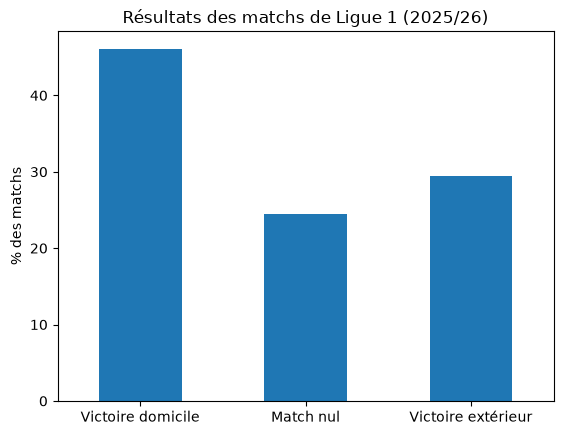

In [9]:
pourcentages = df["FTR"].value_counts(normalize=True).reindex(["H", "D", "A"]) * 100
pourcentages.index = ["Victoire domicile", "Match nul", "Victoire extérieur"]
print(pourcentages.round(1))

pourcentages.plot(kind="bar")
plt.title("Résultats des matchs de Ligue 1 (2025/26)")
plt.ylabel("% des matchs")
plt.xticks(rotation=0)
plt.show()

In [10]:
# Deuxième angle : buts moyens marqués à domicile et à l'extérieur
print("Buts à domicile par match   :", round(df["FTHG"].mean(), 2))
print("Buts à l'extérieur par match:", round(df["FTAG"].mean(), 2))

Buts à domicile par match   : 1.58
Buts à l'extérieur par match: 1.24


Sur cette saison, l'avantage à domicile est net. Mais une seule saison ne suffit pas pour conclure : on vérifie maintenant sur 5 saisons.

## Partie 2 : vérifier sur 5 saisons

### 2.1 Assembler les fichiers
On lit chaque fichier, on ajoute une colonne `Saison` pour garder l'origine de chaque match, puis on empile les tableaux avec `pd.concat`.

In [11]:
saisons = ["season-2122", "season-2223", "season-2324", "season-2425", "season-2526"]

tableaux = []
for nom in saisons:
    t = pd.read_csv(nom + ".csv")
    t["Saison"] = nom[-4:]    # ex. "2526"
    tableaux.append(t[["Saison", "Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG", "FTR"]])

df_all = pd.concat(tableaux, ignore_index=True)
print(df_all.shape)
df_all["Saison"].value_counts().sort_index()   # matchs par saison

(1678, 7)


Saison
2122    380
2223    380
2324    306
2425    306
2526    306
Name: count, dtype: int64

Attendu : 380 matchs pour 2021/22 et 2022/23 (20 équipes), 306 pour les trois saisons suivantes (18 équipes), soit 1 678 matchs au total.

### 2.2 Résultats par saison
`pd.crosstab` croise deux colonnes (saison en lignes, résultat en colonnes) et compte les matchs de chaque case, comme un `GROUP BY` en SQL. `normalize="index"` divise chaque ligne par son total : chaque saison fait 100 %, ce qui permet de comparer des saisons de 380 et de 306 matchs.

In [12]:
resultats = pd.crosstab(df_all["Saison"], df_all["FTR"], normalize="index") * 100
resultats.round(1)

FTR,A,D,H
Saison,,,
2122,30.5,26.8,42.6
2223,32.9,24.2,42.9
2324,34.3,26.5,39.2
2425,33.0,20.3,46.7
2526,29.4,24.5,46.1


In [13]:
# Écart entre victoires à domicile et victoires à l'extérieur, en points de pourcentage
ecart = resultats["H"] - resultats["A"]
print(ecart.round(1))
print("Écart moyen :", round(ecart.mean(), 1))

Saison
2122    12.1
2223    10.0
2324     4.9
2425    13.7
2526    16.7
dtype: float64
Écart moyen : 11.5


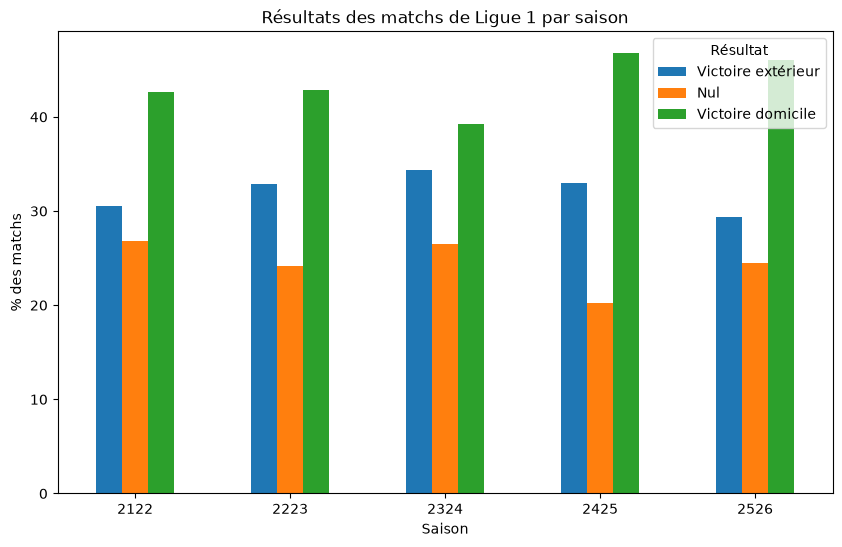

In [14]:
resultats.plot(kind="bar", figsize=(10, 6))
plt.title("Résultats des matchs de Ligue 1 par saison")
plt.xlabel("Saison")
plt.ylabel("% des matchs")
plt.xticks(rotation=0)
plt.legend(title="Résultat", labels=["Victoire extérieur", "Nul", "Victoire domicile"])
plt.show()

## Conclusion

L'objectif de cette analyse était de vérifier si jouer à domicile donne un avantage en Ligue 1. J'ai étudié 5 saisons (2021/22 à 2025/26), soit 1 678 matchs, à partir des données de football-data.co.uk.

Les résultats montrent un avantage net pour les équipes qui jouent à domicile, dans chacune des 5 saisons : elles remportent entre 39,2 % et 46,7 % de leurs matchs, contre 29,4 % à 34,3 % pour les équipes à l'extérieur. L'écart moyen est d'environ 11 points. La saison 2025/26 a l'écart le plus élevé (16,7 points), et 2024/25 le plus haut pourcentage de victoires à domicile (46,7 %). La saison 2023/24 se distingue par un écart nettement plus faible (4,9 points), sans que l'avantage disparaisse.

**Limites :** l'analyse porte sur 5 saisons et une seule ligue, et je n'ai pas fait de test statistique pour confirmer que les écarts ne sont pas dus au hasard. Les données ne permettent pas non plus d'expliquer pourquoi 2023/24 est différente.